# Aula 4 · Prever um número: o caudal do rio

**VERSÃO DO FACILITADOR: tudo resolvido, com notas.** Não copiar para os computadores dos alunos.

**10 minutos (12:55–13:05) · aula guiada, em pares** · a seguir: a Prática 4

**O que vamos fazer:** **prever um número**: quanta água vai passar no rio daqui a 3 dias, a partir do caudal de hoje e da chuva dos últimos dias. Treinamos com o passado e testamos com o futuro.

**Os dados:** `caudal_e_chuva_diarios.csv` (uma linha por dia, de 2006 a 2026: o caudal do rio e a chuva).  
**Treino e teste:** **treino** = os dias de 2006 a 2018 (4 719); **teste** = os de 2019 a 2026 (2 795).  
**O algoritmo:** regressão linear e árvore de regressão (regressão: prever um número).

| Palavra nova | O que quer dizer |
| --- | --- |
| **regressão** | prever um número (e não uma categoria como água ou não água) |
| **caudal** | quanta água passa no rio por segundo, em metros cúbicos por segundo (m³/s) |
| **alvo** | o número que queremos prever: aqui, o caudal daqui a 3 dias |
| **erro médio** | quanto a previsão falha, em média, em m³/s (em inglês, MAE) |
| **profundidade** | o número de perguntas seguidas de uma árvore de decisão |
| **sobreajuste** | o modelo decora o treino e falha nos dados novos |

**Como trabalhar:** esta é a **aula guiada**: o facilitador mostra no projector e vocês acompanham.
Cliquem numa célula de código (as cinzentas) e carreguem em **Shift + Enter** para a correr, sempre **por ordem**, de
cima para baixo. A seguir vem a **prática**, em que são vocês a escrever o código. Guardem com **Ctrl + S**.

> **Nota para o facilitador.** Objectivo: a regressão, a separação no tempo e o sobreajuste. Tempo: 10 minutos, no projector. A seguir, a Prática 4, a 7 dias. Ligue à plataforma (Módulo 5): o caudal é o que decide o nível de alerta.

## Passo 1 · Abrir as ferramentas

In [1]:
import os, sys
for pasta in [".", os.path.join("..", "..", "2_pratica")]:          # a pasta onde está o ferramentas.py
    if os.path.exists(os.path.join(pasta, "ferramentas.py")):
        sys.path.insert(0, pasta)
        break
from ferramentas import *      # as ferramentas da aula
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
print("Ferramentas prontas.")

Ferramentas prontas.


## Passo 2 · Vinte anos de caudal e de chuva

Uma linha por dia, de 2006 a 2026. `caudal_m3s` é o caudal do Incomáti em Marracuene; `chuva_7d_mm`, `chuva_14d_mm` e `chuva_30d_mm` são a chuva que caiu na bacia do rio nos últimos 7, 14 e 30 dias.

Dias na tabela: 7 517 de 30/01/2006 a 31/08/2026


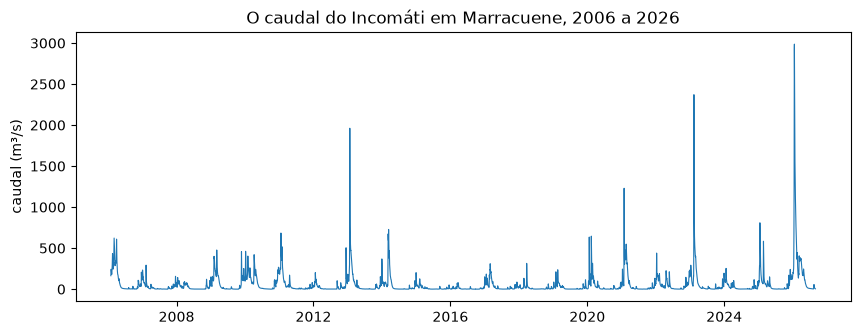

,data,caudal_m3s,chuva_7d_mm,chuva_14d_mm,chuva_30d_mm
7512,2026-08-27,6.5,20.8,32.1,40.1
7513,2026-08-28,5.6,20.7,34.2,40.6
7514,2026-08-29,4.9,20.7,36.3,38.5
7515,2026-08-30,4.4,20.6,36.1,39.0
7516,2026-08-31,4.0,20.7,36.1,41.3


In [2]:
dias = pd.read_csv(encontrar("caudal_e_chuva_diarios.csv"), parse_dates=["data"])
print("Dias na tabela:", numero(len(dias)), "de", dias["data"].min().strftime("%d/%m/%Y"), "a", dias["data"].max().strftime("%d/%m/%Y"))
plt.figure(figsize=(10, 3.5))
plt.plot(dias["data"], dias["caudal_m3s"], lw=0.8)
plt.ylabel("caudal (m³/s)")
plt.title("O caudal do Incomáti em Marracuene, 2006 a 2026")
plt.show()
dias[["data", "caudal_m3s", "chuva_7d_mm", "chuva_14d_mm", "chuva_30d_mm"]].tail()

## Passo 3 · A pergunta: o caudal daqui a 3 dias

Queremos **prever um número**: isto é **regressão**. A coluna com a resposta certa chama-se **alvo**. As **pistas** (as características) são o caudal de hoje e a chuva.

In [3]:
dias["caudal_daqui_a_3_dias"] = dias["caudal_m3s"].shift(-3)    # o alvo: o caudal 3 dias depois
dias = dias.dropna()
PISTAS = ["caudal_m3s", "chuva_7d_mm", "chuva_14d_mm", "chuva_30d_mm"]
ALVO = "caudal_daqui_a_3_dias"
dias[["data"] + PISTAS + [ALVO]].head()

,data,caudal_m3s,chuva_7d_mm,chuva_14d_mm,chuva_30d_mm,caudal_daqui_a_3_dias
0,2006-01-30,163.8,50.5,77.9,211.5,242.2
1,2006-01-31,199.6,45.6,77.9,211.5,236.4
2,2006-02-01,231.5,43.2,77.9,208.3,224.1
3,2006-02-02,242.2,28.2,66.9,201.7,211.1
4,2006-02-03,236.4,21.5,67.0,203.2,193.8


## Passo 4 · Separar no tempo: o exame é o futuro

Para saber se o modelo prevê o futuro, treinamos com os anos **2006 a 2018** e testamos com **2019 a 2026**, anos que ele nunca viu.

Dias de treino: 4719    Dias de teste: 2795


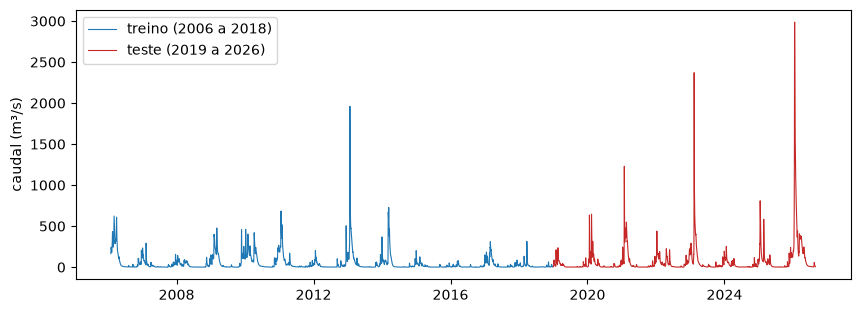

In [4]:
treino = dias[dias["data"].dt.year <= 2018]
teste = dias[dias["data"].dt.year >= 2019]
print("Dias de treino:", len(treino), "   Dias de teste:", len(teste))
plt.figure(figsize=(10, 3.5))
plt.plot(treino["data"], treino["caudal_m3s"], lw=0.8, label="treino (2006 a 2018)")
plt.plot(teste["data"], teste["caudal_m3s"], lw=0.8, color="#C62828", label="teste (2019 a 2026)")
plt.ylabel("caudal (m³/s)")
plt.legend()
plt.show()

## Passo 5 · A regressão linear

A **regressão linear** aprende um peso para cada pista: caudal daqui a 3 dias ≈ peso 1 × caudal de hoje + peso 2 × chuva de 7 dias + ... Os pesos são o que o modelo aprende com o treino.

In [5]:
linear = LinearRegression()
linear.fit(treino[PISTAS], treino[ALVO])
for pista, peso in zip(PISTAS, linear.coef_):
    print(pista, "peso", numero(peso, 2))
erro_treino = (treino[ALVO] - linear.predict(treino[PISTAS])).abs().mean()
erro_teste = (teste[ALVO] - linear.predict(teste[PISTAS])).abs().mean()
igual_a_hoje = (teste[ALVO] - teste["caudal_m3s"]).abs().mean()
print()
print("Erro médio no TREINO:", numero(erro_treino, 1), "m³/s")
print("Erro médio no TESTE: ", numero(erro_teste, 1), "m³/s")
print("Se disséssemos sempre «fica igual a hoje», o erro no teste seria", numero(igual_a_hoje, 1), "m³/s")

caudal_m3s peso 0,72
chuva_7d_mm peso 1,18
chuva_14d_mm peso -0,23
chuva_30d_mm peso 0,14

Erro médio no TREINO: 17,9 m³/s
Erro médio no TESTE:  26,3 m³/s
Se disséssemos sempre «fica igual a hoje», o erro no teste seria 28,7 m³/s


O **erro médio** é quanto a previsão falha, em média, em m³/s. Quanto menor, melhor. O modelo erra mais no teste do que no treino: é normal, os anos de teste são novos para ele.

> **Nota para o facilitador.** Resultado esperado: erro no treino 17,9 m³/s, no teste 26,3 m³/s; «igual a hoje» 28,7 m³/s. O modelo é melhor do que não fazer nada, mas pouco. O peso maior é o do caudal de hoje: o rio de amanhã parece-se com o de hoje.

## Passo 6 · A cheia de Janeiro de 2026

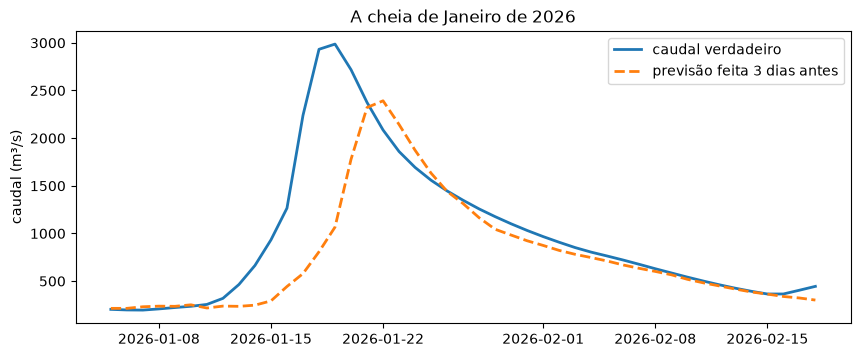

In [6]:
janeiro = teste[(teste["data"] >= "2026-01-01") & (teste["data"] <= "2026-02-15")]
dia_previsto = janeiro["data"] + pd.Timedelta(days=3)
plt.figure(figsize=(10, 3.8))
plt.plot(dia_previsto, janeiro[ALVO], lw=2, label="caudal verdadeiro")
plt.plot(dia_previsto, linear.predict(janeiro[PISTAS]), lw=2, ls="--", label="previsão feita 3 dias antes")
plt.ylabel("caudal (m³/s)")
plt.title("A cheia de Janeiro de 2026")
plt.legend()
plt.show()

O modelo vê a subida, mas **chega tarde e fica abaixo**: só conhece a chuva que já caiu. Por isso a plataforma EYES TO EARTH usa também as previsões do modelo europeu **GloFAS**, que entram com a chuva prevista para os próximos dias.

> **Nota para o facilitador.** Mostre no gráfico o dia 13 de Janeiro: o modelo prevê muito menos do que o caudal que veio. Esta é a melhor ponte para o Módulo 5: as previsões de chuva dão dias de avanço.

## Passo 7 · A árvore de regressão e o sobreajuste

Uma árvore de decisão também prevê números. Quanto mais funda (mais perguntas seguidas), melhor decora o treino. Mas o que interessa é o erro no **teste**.

In [7]:
for profundidade in [1, 3, 5, 10, 20]:
    arvore = DecisionTreeRegressor(max_depth=profundidade, random_state=0).fit(treino[PISTAS], treino[ALVO])
    e_treino = (treino[ALVO] - arvore.predict(treino[PISTAS])).abs().mean()
    e_teste = (teste[ALVO] - arvore.predict(teste[PISTAS])).abs().mean()
    print(f"Profundidade {profundidade}: erro no treino", numero(e_treino, 1), "m³/s, erro no teste", numero(e_teste, 1), "m³/s")

Profundidade 1: erro no treino 34,7 m³/s, erro no teste 52,7 m³/s
Profundidade 3: erro no treino 17,7 m³/s, erro no teste 35,1 m³/s
Profundidade 5: erro no treino 12,9 m³/s, erro no teste 34,7 m³/s
Profundidade 10: erro no treino 5,7 m³/s, erro no teste 38,1 m³/s
Profundidade 20: erro no treino 0,1 m³/s, erro no teste 39,4 m³/s


Com profundidade 20, o erro no treino é quase 0, mas no teste é maior: a árvore **decorou** o treino. Chama-se **sobreajuste**.

> **Nota para o facilitador.** Resultados esperados (erro no treino / no teste, em m³/s): profundidade 1: 34,7 / 52,7; profundidade 3: 17,7 / 35,1; profundidade 5: 12,9 / 34,7; profundidade 10: 5,7 / 38,1; profundidade 20: 0,1 / 39,4. A melhor é 5.

## O que aprendemos

- **Regressão**: prever um número (o caudal), não uma categoria.
- Num modelo de previsão, separa-se no **tempo**: treina-se com o passado e testa-se com o futuro.
- O **erro médio** diz quanto o modelo falha, nas unidades do alvo (m³/s).
- Uma árvore muito funda **decora** o treino (**sobreajuste**) e erra mais nos dados novos.
- Um modelo só sabe o que está nos dados: sem a chuva prevista, chega tarde à cheia.

## Guardar os modelos e as separações (só na versão do facilitador)

Ficam nas pastas `modelos_treinados/` e `separacoes/`, ao lado deste notebook. Para usar um modelo noutro notebook: `modelo = joblib.load("modelos_treinados/...joblib")`.

In [8]:
import joblib
os.makedirs("modelos_treinados", exist_ok=True)
os.makedirs("separacoes", exist_ok=True)
joblib.dump(linear, "modelos_treinados/aula4_regressao_linear.joblib")
melhor = DecisionTreeRegressor(max_depth=5, random_state=0).fit(treino[PISTAS], treino[ALVO])
joblib.dump(melhor, "modelos_treinados/aula4_arvore_profundidade_5.joblib")
treino.to_csv("separacoes/aula4_treino_2006_a_2018.csv", index=False)
teste.to_csv("separacoes/aula4_teste_2019_a_2026.csv", index=False)
print("Guardado em modelos_treinados/ e separacoes/.")

Guardado em modelos_treinados/ e separacoes/.


## Se aparecer um erro

Leiam a **última linha** da mensagem vermelha.

| A última linha diz | O que fazer |
| --- | --- |
| `NameError: name '...' is not defined` | Saltaram uma célula. Corram as células por ordem, a partir do Passo 1. |
| `FileNotFoundError: Não encontrei ...` | Abram o notebook a partir da pasta `Workshop_2/2_pratica`. |
| `ModuleNotFoundError` | Falta uma biblioteca neste computador: chamem um facilitador. |
| `NotFittedError` ou «O modelo ainda não foi treinado» | Falta treinar o modelo: corram a célula com `.fit(...)`. |
| `SyntaxError` | Falta uma aspa, um parêntese ou uma vírgula. Comparem com o exemplo. |
| «Falta preencher» | Troquem os `...` pela vossa resposta. |

Se nada resultar: menu **Kernel**, depois **Restart Kernel and Run All Cells**.